# 집값 예측 컴피티션: 회귀 모델 개선 기록(38,019에서 20,215까지) — 공정 검증 버전

**AI 데이터 인텔리전스 › 필수 머신러닝 › 집값 예측 컴피티션** · 공정 검증 노트북

**[Modulabs-DI2기] House Price Prediction** · 지표: RMSE(달러)

> [!IMPORTANT]
> **이 노트북의 원칙 — test는 마지막 예측에서 한 번만 읽는다.**
> 모델·이상치 기준·블렌드 비중·보정 강도는 모두 **train만으로**, 실행 전에 정해 둔 규칙(4장)에 따라 **교차검증으로 자동 선택**한다.
> test의 정답·분포·리더보드 점수는 어떤 선택에도 쓰지 않는다.

**왜 다시 만들었나** — 처음 과정에서는 이상치 기준(2.5σ)·보정 강도(0.04)·블렌드 비중을 **리더보드 점수를 보고** 골랐고(리더보드 18,150, 1위),
검증 채점 범위도 test의 면적 분포를 보고 정했다. 리더보드는 test 정답으로 매긴 점수이므로 이는 **test 정보를 간접적으로 쓴 튜닝**이다.
이 노트북은 그 선택을 모두 버리고, test를 보지 않는 절차로 모델을 다시 고른 결과다. 처음 과정은 10장에 **반면교사**로 기록한다.

| 항목 | 리더보드 |
|---|---|
| 1차 제출 (템플릿 버그 수정 후 LinearRegression) | 38,019 |
| 리더보드 튜닝으로 고른 모델 (17차, 공정하지 않음) | 18,150 |
| **이 노트북의 공정 모델 (1회 제출)** | **20,215** |

### 목차
1. 데이터 불러오기 · 2. 데이터 탐색(EDA) · 3. 전처리 · 4. 사전 등록한 검증 규칙 · 5. 교차검증 실행
6. 단일 모델 비교 · 7. 자동 선택 결과(앙상블·이상치) · 8. 늘이기 보정 · 9. 최종 학습과 제출 파일 · 10. 제출 이력과 반면교사 · 11. 학습노트

> 실행 시간: 5장 교차검증이 약 20분 걸린다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, warnings
warnings.filterwarnings("ignore")                 # pandas 버전 안내 경고 숨김(결과에 영향 없음)

from sklearn import set_config
set_config(display="text")                         # 한글 윈도우에서 모델 HTML 표시 에러 방지
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False

DATA = "./" if os.path.exists("./train.csv") else "../"   # 데이터 위치: 같은 폴더 또는 상위 폴더

## 1. 데이터 불러오기

**train만 읽는다.** test는 9장에서 최종 예측할 때 처음 읽는다.
원본 Kaggle 데이터는 이 대회 test의 정답을 포함하므로 사용하지 않는다.

In [2]:
train_raw = pd.read_csv(DATA + "train.csv")
print("train:", train_raw.shape)

train: (1168, 81)


## 2. 데이터 탐색 (EDA) — train만 본다

In [3]:
na = train_raw.isnull().sum(); na = na[na > 0].sort_values(ascending=False)
print(f"결측이 있는 컬럼 {len(na)}개"); print(na)

결측이 있는 컬럼 19개
PoolQC          1162
MiscFeature     1120
Alley           1098
Fence            941
MasVnrType       694
FireplaceQu      545
LotFrontage      218
GarageType        69
GarageYrBlt       69
GarageFinish      69
GarageQual        69
GarageCond        69
BsmtExposure      24
BsmtFinType2      24
BsmtQual          23
BsmtCond          23
BsmtFinType1      23
MasVnrArea         8
Electrical         1
dtype: int64


**해석** — 결측이 모두 '모름'은 아니다. `PoolQC`·`MiscFeature`·`Alley`·`Fence`·`FireplaceQu`는 대부분 **그 시설이 없음**이고,
Garage 관련 5개가 모두 69인 것은 같은 69채가 '차고 없음'이라는 뜻이다. `LotFrontage`(218)는 진짜 모르는 값이다.

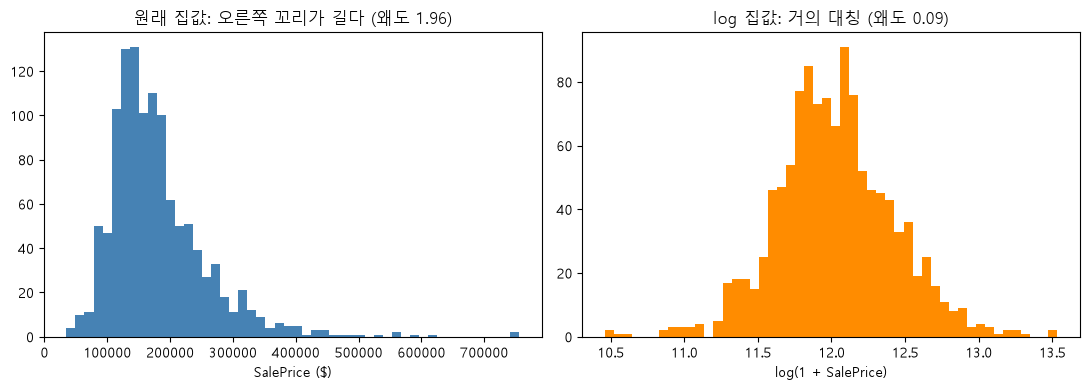

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(train_raw["SalePrice"], bins=50, color="steelblue")
axes[0].set_title(f"원래 집값: 오른쪽 꼬리가 길다 (왜도 {train_raw['SalePrice'].skew():.2f})"); axes[0].set_xlabel("SalePrice ($)")
axes[1].hist(np.log1p(train_raw["SalePrice"]), bins=50, color="darkorange")
axes[1].set_title(f"log 집값: 거의 대칭 (왜도 {np.log1p(train_raw['SalePrice']).skew():.2f})"); axes[1].set_xlabel("log(1 + SalePrice)")
plt.tight_layout(); plt.show()

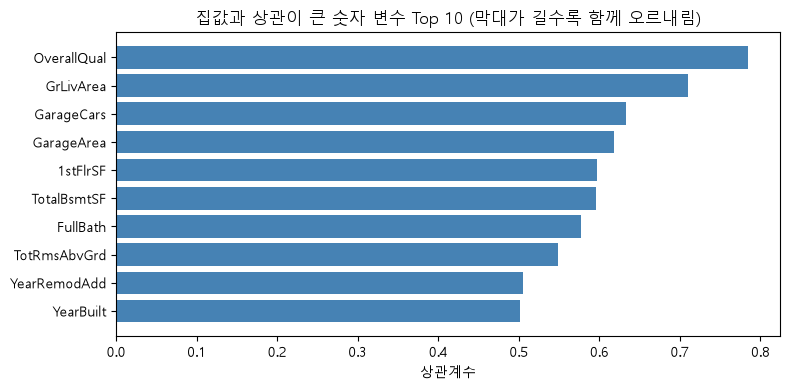

In [5]:
corr = train_raw.select_dtypes("number").drop(columns="Id").corr()["SalePrice"]
top10 = corr.drop("SalePrice").sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 4)); plt.barh(top10.index[::-1], top10.values[::-1], color="steelblue")
plt.title("집값과 상관이 큰 숫자 변수 Top 10 (막대가 길수록 함께 오르내림)"); plt.xlabel("상관계수")
plt.tight_layout(); plt.show()

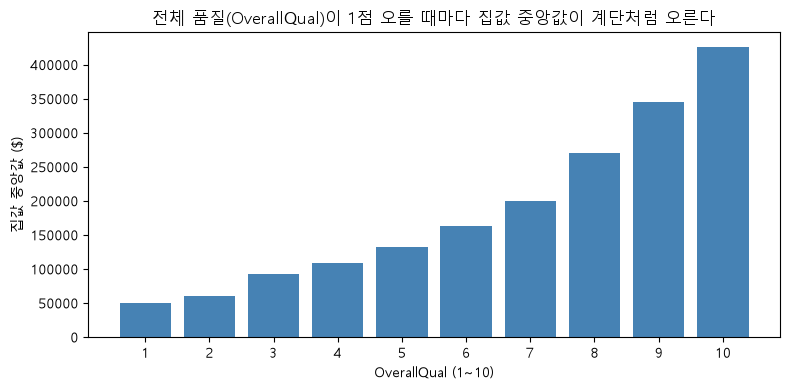

In [6]:
qual = train_raw.groupby("OverallQual")["SalePrice"].median()
plt.figure(figsize=(8, 4)); plt.bar(qual.index, qual.values, color="steelblue")
plt.title("전체 품질(OverallQual)이 1점 오를 때마다 집값 중앙값이 계단처럼 오른다")
plt.xlabel("OverallQual (1~10)"); plt.ylabel("집값 중앙값 ($)"); plt.xticks(qual.index); plt.tight_layout(); plt.show()

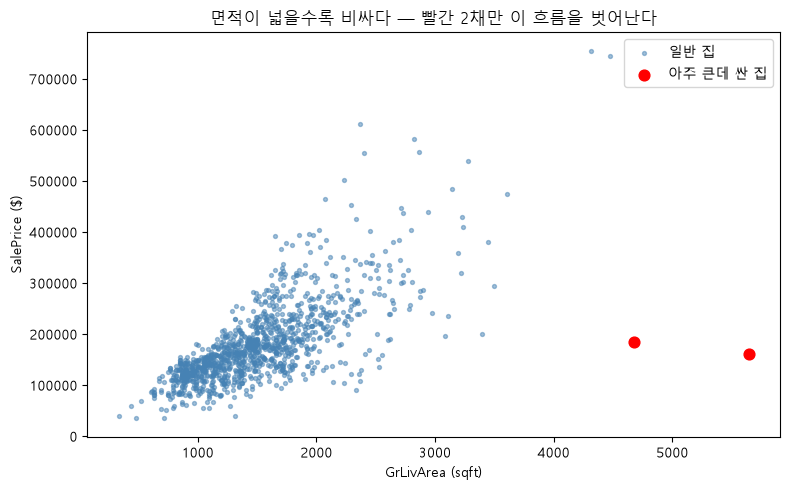

       Id  GrLivArea  OverallQual SaleCondition  SalePrice
64   1299       5642           10       Partial     160000
373   524       4676           10       Partial     184750


In [7]:
big_cheap = (train_raw["GrLivArea"] > 4000) & (train_raw["SalePrice"] < 300000)
plt.figure(figsize=(8, 5))
plt.scatter(train_raw.loc[~big_cheap, "GrLivArea"], train_raw.loc[~big_cheap, "SalePrice"], s=8, alpha=0.5, color="steelblue", label="일반 집")
plt.scatter(train_raw.loc[big_cheap, "GrLivArea"], train_raw.loc[big_cheap, "SalePrice"], s=60, color="red", label="아주 큰데 싼 집")
plt.title("면적이 넓을수록 비싸다 — 빨간 2채만 이 흐름을 벗어난다")
plt.xlabel("GrLivArea (sqft)"); plt.ylabel("SalePrice ($)"); plt.legend(); plt.tight_layout(); plt.show()
print(train_raw.loc[big_cheap, ["Id", "GrLivArea", "OverallQual", "SaleCondition", "SalePrice"]])

#### EDA 정리
1. 집값은 비싼 집 쪽 꼬리가 길다(왜도 1.96) → **log(집값)으로 학습**하고 예측 후 달러로 되돌린다.
2. 전체 품질(0.79)과 거실 면적(0.71)이 가장 강하다 — "얼마나 좋은 집이고, 얼마나 큰가".
3. 품질 1점마다 집값 중앙값이 꾸준히 오른다(log 공간에서 거의 직선) → 선형 모델이 강할 것이라는 가설.
4. 4,000sqft가 넘는데 30만 달러 미만인 2채(Id 1299, 524)는 품질 10점인데 '공사 중 판매(Partial)'다 → **학습에서 제외**한다(train 정보만으로 내린 판단).

## 3. 전처리

### 3-1. 템플릿의 버그를 train 안에서 재현한다
템플릿은 test를 **test 자신의** 통계로 채우고, test만 따로 `get_dummies(drop_first=True)` 했다(1차 제출 전 예측 평균 8.9만 달러, 음수 28개로 붕괴).
test를 보지 않고 같은 현상을 보이기 위해, train을 80:20으로 나눠 **검증 데이터에 템플릿 방식을 그대로 적용**해 본다.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

part_tr, part_va = train_test_split(train_raw, test_size=0.2, random_state=42)
def fill_with(df, ref):                       # ref의 중앙값·최빈값으로 결측을 채운다
    d = df.fillna(ref.median(numeric_only=True))
    for col in d.select_dtypes(include="object"):
        d[col] = d[col].fillna(ref[col].mode()[0])
    return d

X_a = pd.get_dummies(fill_with(part_tr, part_tr), drop_first=True).drop(columns="SalePrice")
base_lr = LinearRegression().fit(X_a, part_tr["SalePrice"])
template_way = pd.get_dummies(fill_with(part_va, part_va).drop(columns="SalePrice"), drop_first=True).reindex(columns=X_a.columns, fill_value=0)
correct_way  = pd.get_dummies(fill_with(part_va, part_tr).drop(columns="SalePrice")).reindex(columns=X_a.columns, fill_value=0)
for name, Xv in [("템플릿 방식 (검증 데이터 자기 기준)", template_way), ("train 기준으로 같은 처리", correct_way)]:
    p = base_lr.predict(Xv)
    print(f"{name}: RMSE {np.sqrt(np.mean((p - part_va['SalePrice'])**2)):,.0f}")

템플릿 방식 (검증 데이터 자기 기준): RMSE 100,051
train 기준으로 같은 처리: RMSE 44,238


같은 모델인데 전처리 기준만 달라져도 RMSE가 두 배 넘게 차이 난다. **채우는 값은 train에서만 구하고, train과 test에 같은 함수를 적용한다**(Ch4).

In [9]:
def make_preprocess(ref):
    """ref(학습 데이터)의 중앙값·최빈값을 기억하는 전처리 함수를 만든다"""
    median = ref.median(numeric_only=True)
    mode = {col: ref[col].mode()[0] for col in ref.select_dtypes(include="object")}
    def preprocess(df):
        df = df.fillna(median)
        for col, value in mode.items():
            df[col] = df[col].fillna(value)
        return df
    return preprocess

def encode(train_part, other_part):
    """train_part 기준으로 원-핫 인코딩하고 other_part를 같은 컬럼에 맞춘다"""
    prep = make_preprocess(train_part)
    X_tr = pd.get_dummies(prep(train_part), drop_first=True).drop(columns=["SalePrice"], errors="ignore")
    X_ot = pd.get_dummies(prep(other_part)).reindex(columns=X_tr.columns, fill_value=0)
    return X_tr.astype(float), X_ot.astype(float)

## 4. 사전 등록한 검증 규칙

아래 규칙을 **5장을 실행하기 전에** 정했다. 결과를 보고 규칙을 바꾸지 않는다.

| 항목 | 규칙 |
|---|---|
| 데이터 | train 1,168채만 사용. test는 9장에서 예측할 때만 읽는다 |
| 전처리 | 각 fold의 **학습 데이터만으로** 결측 채움 값과 원-핫 컬럼을 정한다 |
| 채점 | 검증 fold의 **모든 집**, RMSE(달러). 아무 집도 채점에서 빼지 않는다 |
| 반복 | 5-fold × 3회 = 15번 검증, 평균으로 비교 |
| 학습 이상치 | EDA의 '큰데 싼 집' 2채는 항상 제외. 잔차 기준 후보 z ∈ {없음, 3.5, 3.0, 2.5} |
| 모델 | Ridge(α=3) · Lasso(α=0.0005) · GBR(깊이3) · GBR(깊이4) · XGBoost |
| 블렌드 | 선형(Ridge·Lasso 평균) 비중 w ∈ {0, 0.3, 0.5, 0.7, 1}, 나머지는 트리 3개 평균 |
| 보정 | 강도 a ∈ {0, 0.01, …, 0.05} |
| 선택 | **CV 평균 최저** 조합. 최저와 50달러 이내 차이면 더 단순한 쪽(보정 작게 → 이상치 제거 적게) |

> **남아 있는 편향 (공개)** — 선택 절차는 test를 쓰지 않지만, **후보 목록**(잔차 기준 2.5σ, 보정 0.04, 깊이 4 GBR 등)은 처음 과정에서 리더보드를 보며 얻은 경험으로 만들었다.
> 이 편향은 지울 수 없으므로 공개해 둔다. 또 120개 조합 중 CV 최저를 고르므로, 선택된 조합의 CV 점수는 실제보다 **낙관적**일 수 있다.
> 선택 절차 전체에 대한 독립 평가는 test에 **한 번만** 제출한 리더보드 점수다(10장).

In [10]:
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from xgboost import XGBRegressor

MODELS = {
    "Ridge":  lambda: make_pipeline(RobustScaler(), Ridge(alpha=3)),
    "Lasso":  lambda: make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000)),
    "GBR":    lambda: GradientBoostingRegressor(n_estimators=1500, learning_rate=0.03, max_depth=3,
                                                subsample=0.8, max_features="sqrt", random_state=42),
    "GBR_d4": lambda: GradientBoostingRegressor(n_estimators=2000, learning_rate=0.02, max_depth=4, subsample=0.8,
                                                max_features="sqrt", min_samples_leaf=5, random_state=42),
    "XGB":    lambda: XGBRegressor(n_estimators=2000, learning_rate=0.02, max_depth=3, subsample=0.8,
                                   colsample_bytree=0.3, min_child_weight=2, random_state=42),
}
Z_OPTIONS = [None, 3.5, 3.0, 2.5]
W_OPTIONS = [0, 0.3, 0.5, 0.7, 1]
A_OPTIONS = [0, 0.01, 0.02, 0.03, 0.04, 0.05]

def outlier_mask(X, y, z):
    """학습에 쓸 집 표시: 큰데 싼 2채 제외 + (z가 있으면) 잔차 z 이상 제외"""
    keep = ~((X["GrLivArea"] > 4000).values & (y < 300000))
    if z is not None:
        Xk, lk = X[keep], np.log1p(y[keep])
        resid = lk - make_pipeline(RobustScaler(), Ridge(alpha=10)).fit(Xk, lk).predict(Xk)
        zz = np.abs((resid - resid.mean()) / resid.std())
        idx = np.where(keep)[0]; keep[idx[zz >= z]] = False
    return keep

def stretch(price, a):
    return price * (price / 163000) ** a

## 5. 교차검증 실행 (약 20분)

15개 fold 각각에서 ① fold 학습 데이터로 전처리 기준을 정하고 ② 이상치 후보별로 ③ 모델 5개를 학습해 검증 fold를 예측한다.

In [11]:
folds = list(RepeatedKFold(n_splits=5, n_repeats=3, random_state=0).split(train_raw))
pred = {(z, m): [] for z in Z_OPTIONS for m in MODELS}    # log 예측
y_val = []
for i, (tr_idx, va_idx) in enumerate(folds):
    part_tr, part_va = train_raw.iloc[tr_idx], train_raw.iloc[va_idx]
    X_tr, X_va = encode(part_tr, part_va)
    X_tr, X_va = X_tr.drop(columns="Id"), X_va.drop(columns="Id")
    y_tr = part_tr["SalePrice"].values
    for z in Z_OPTIONS:
        keep = outlier_mask(X_tr, y_tr, z)
        for name, make in MODELS.items():
            pred[(z, name)].append(make().fit(X_tr[keep], np.log1p(y_tr[keep])).predict(X_va))
    y_val.append(part_va["SalePrice"].values)
    print(f"fold {i+1}/15 완료", end=" | ")

def fold_rmse(log_preds, a=0.0):
    return np.array([np.sqrt(np.mean((stretch(np.expm1(p), a) - t) ** 2)) for p, t in zip(log_preds, y_val)])

def blend(z, w):
    return [w * (pred[(z, "Ridge")][i] + pred[(z, "Lasso")][i]) / 2
            + (1 - w) * (pred[(z, "GBR")][i] + pred[(z, "GBR_d4")][i] + pred[(z, "XGB")][i]) / 3 for i in range(len(folds))]

fold 1/15 완료 | 

fold 2/15 완료 | 

fold 3/15 완료 | 

fold 4/15 완료 | 

fold 5/15 완료 | 

fold 6/15 완료 | 

... (5 outputs left out)

fold 12/15 완료 | 

fold 13/15 완료 | 

fold 14/15 완료 | 

fold 15/15 완료 | 

## 6. 단일 모델 비교 (이상치는 큰데 싼 2채만 제외, 보정 없음)

XGB       28778.0
GBR_d4    28834.0
GBR       28926.0
Ridge     56809.0
Lasso     58240.0
dtype: float64


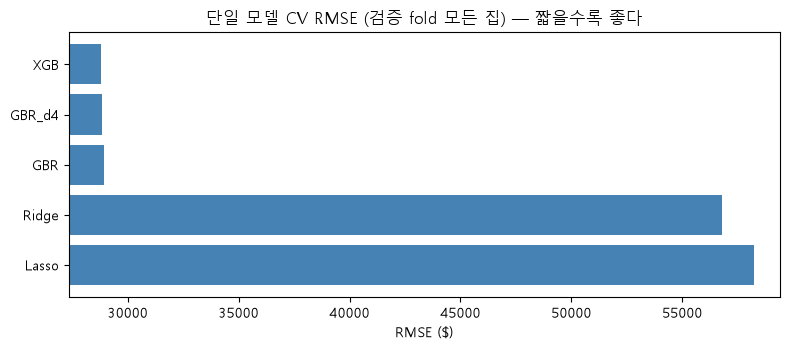

In [12]:
single = pd.Series({name: fold_rmse(pred[(None, name)]).mean() for name in MODELS}).sort_values()
print(single.round(0))
plt.figure(figsize=(8, 3.6)); plt.barh(single.index[::-1], single.values[::-1], color="steelblue")
plt.xlim(single.min() * 0.95, single.max() * 1.02)
plt.title("단일 모델 CV RMSE (검증 fold 모든 집) — 짧을수록 좋다"); plt.xlabel("RMSE ($)")
plt.tight_layout(); plt.show()

**해석** — 검증 fold의 **모든 집**을 채점하면 트리 모델(약 28,800)이 선형 모델(약 56,800~58,200)보다 훨씬 좋다.
선형 모델의 점수를 크게 나쁘게 만든 것은 검증에 섞인 **초대형 저가 주택 2채**(5,642sqft·16만 달러 등)다. 학습에서는 이 집들을 뺐기 때문에,
선형 모델은 면적에 비례해 값을 키워 이 집들을 크게 과대 예측한다(**외삽**). 트리는 학습 범위 안의 값만 내놓아 크게 빗나가지 않는다.

> 처음 과정에서 "선형 모델이 더 강하다"고 본 것은 이 2채를 **가격 기준으로 채점에서 뺀** 결과였다. 정답을 보고 평가 대상을 고르면 모델의 강약 판단까지 달라진다.

## 7. 자동 선택 결과 — 이상치 기준 × 블렌드 비중 × 보정 강도

In [13]:
rows = []
for z in Z_OPTIONS:
    for w in W_OPTIONS:
        lp = blend(z, w)
        for a in A_OPTIONS:
            s = fold_rmse(lp, a)
            rows.append({"잔차 기준 z": "없음" if z is None else z, "선형 비중 w": w, "보정 a": a,
                         "CV RMSE": s.mean(), "fold 표준편차": s.std(ddof=1), "_z": z})
table = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
show = table.drop(columns="_z").head(10).copy()
show[["CV RMSE", "fold 표준편차"]] = show[["CV RMSE", "fold 표준편차"]].round(0)
print(show.to_string())

# 사전 등록한 선택 규칙: 최저와 50달러 이내면 보정 작게 → 이상치 제거 적게
best_score = table["CV RMSE"].min()
near = table[table["CV RMSE"] <= best_score + 50].copy()
z_rank = {None: 0, 3.5: 1, 3.0: 2, 2.5: 3}
near["_zr"] = near["_z"].map(z_rank)
choice = near.sort_values(["보정 a", "_zr", "CV RMSE"]).iloc[0]
BEST_Z, BEST_W, BEST_A = choice["_z"], float(choice["선형 비중 w"]), float(choice["보정 a"])
print(f"\n선택: 잔차 기준 z = {'없음' if BEST_Z is None else BEST_Z}, 선형 비중 w = {BEST_W}, 보정 a = {BEST_A} "
      f"→ CV {choice['CV RMSE']:,.0f} (최저 {best_score:,.0f})")

  잔차 기준 z  선형 비중 w  보정 a  CV RMSE  fold 표준편차
0     3.0      0.0  0.00  27956.0     7337.0
1     3.0      0.0  0.01  27963.0     7631.0
2     3.0      0.0  0.02  28008.0     7927.0
3     3.0      0.0  0.03  28094.0     8222.0
4     3.0      0.0  0.04  28221.0     8515.0
5     3.5      0.0  0.00  28251.0     7332.0
6     3.5      0.0  0.01  28269.0     7636.0
7     2.5      0.0  0.00  28273.0     7965.0
8     2.5      0.0  0.01  28283.0     8280.0
9     3.5      0.0  0.02  28326.0     7941.0

선택: 잔차 기준 z = 3.0, 선형 비중 w = 0.0, 보정 a = 0.0 → CV 27,956 (최저 27,956)


In [14]:
best_single = single.index[0]
summary = pd.Series({
    f"최고 단일 모델 ({best_single})": single.iloc[0],
    "블렌드 (선택된 z·w, 보정 없음)": fold_rmse(blend(BEST_Z, BEST_W)).mean(),
    "블렌드 + 선택된 보정": fold_rmse(blend(BEST_Z, BEST_W), BEST_A).mean(),
})
print(summary.round(0))

최고 단일 모델 (XGB)          28778.0
블렌드 (선택된 z·w, 보정 없음)    27956.0
블렌드 + 선택된 보정            27956.0
dtype: float64


**선택 결과** — 규칙에 따라 **잔차 기준 3σ, 선형 비중 0(트리 3개 평균), 보정 없음**이 선택됐다.
모든 집을 채점하는 규칙에서는 선형 모델을 섞는 순간 초대형 주택의 외삽 오차가 그대로 들어오므로, 트리만 쓰는 조합이 가장 좋았다.
처음 과정(리더보드 튜닝)의 선택(선형 50%, 2.5σ, 보정 0.04)과 다르다 — 선택 절차가 리더보드 경험 쪽으로 끌려가지 않았다는 근거이기도 하다.

## 8. 늘이기 보정

규제가 걸린 모델은 예측을 평균 쪽으로 끌어당기는 경향이 있어, 예측을 중앙값(163,000달러) 기준으로 살짝 펴는 보정을 후보로 넣었다.
$$\text{보정 예측} = p \times \left(\frac{p}{163{,}000}\right)^{a}$$
아래는 선택된 이상치 기준·블렌드 비중에서 보정 강도별 결과다. **fold 간 편차**도 함께 본다.

In [15]:
lp = blend(BEST_Z, BEST_W)
base = fold_rmse(lp, 0)
rows = []
for a in A_OPTIONS:
    s = fold_rmse(lp, a)
    rows.append({"보정 a": a, "CV RMSE": s.mean(), "보정 없음보다 좋아진 fold": f"{(s < base).sum()}/15", "평균 변화": (s - base).mean()})
out = pd.DataFrame(rows); out[["CV RMSE", "평균 변화"]] = out[["CV RMSE", "평균 변화"]].round(0)
print(out.to_string(index=False))

 보정 a  CV RMSE 보정 없음보다 좋아진 fold  평균 변화
 0.00  27956.0             0/15    0.0
 0.01  27963.0             9/15    7.0
 0.02  28008.0             9/15   53.0
 0.03  28094.0             8/15  138.0
 0.04  28221.0             8/15  265.0
 0.05  28389.0             8/15  433.0


**해석** — 보정은 15개 fold 중 8~9개에서만 좋아졌고, 평균으로는 오히려 나빠졌다. 트리 모델은 선형 모델처럼 예측을 평균 쪽으로 강하게 끌어당기지 않으므로 보정이 필요 없다는 결과다.
처음 과정에서 보정이 리더보드를 크게 낮춘 것(18,805 → 18,352)은 선형 비중이 큰 모델이었기 때문이고, 그 강도(0.04)는 리더보드로 고른 값이었다.

## 9. 최종 학습과 제출 파일 — 여기서 test를 처음 읽는다

선택된 설정으로 train 전체를 학습하고 test를 한 번 예측한다. 예측값 점검(평균·음수 개수)은 정답 없이 하는 **형식 점검**이며, 이 결과로 아무것도 바꾸지 않는다.

In [16]:
class FairBlendModel:
    """7장에서 자동 선택된 설정(z, w, a)으로 학습·예측"""
    def __init__(self, z, w, a):
        self.z, self.w, self.a = z, w, a
    def fit(self, X, y):
        X = X.drop(columns="Id"); y = np.asarray(y)
        keep = outlier_mask(X, y, self.z)
        self.n_removed = int((~keep).sum())
        self.models = {name: make().fit(X[keep], np.log1p(y[keep])) for name, make in MODELS.items()}
        return self
    def predict(self, X):
        X = X.drop(columns="Id")
        p = {name: m.predict(X) for name, m in self.models.items()}
        log_pred = self.w * (p["Ridge"] + p["Lasso"]) / 2 + (1 - self.w) * (p["GBR"] + p["GBR_d4"] + p["XGB"]) / 3
        return stretch(np.expm1(log_pred), self.a)

test_raw = pd.read_csv(DATA + "test.csv")                   # ← test를 처음 읽는 곳
X_full, X_test = encode(train_raw, test_raw)
final = FairBlendModel(BEST_Z, BEST_W, BEST_A).fit(X_full, train_raw["SalePrice"])
test_pred = final.predict(X_test)
print("학습에서 제외한 집:", final.n_removed, "채")
print(pd.Series(test_pred).describe().round(0))
print("음수 예측:", (test_pred < 0).sum(), "개 / 빈칸:", np.isnan(test_pred).sum(), "개")

sample = pd.read_csv(DATA + "sample_submission.csv")
submission = pd.DataFrame({"Id": test_raw["Id"], "SalePrice": test_pred})
assert (submission["Id"].values == sample["Id"].values).all()
submission.to_csv("submission_fair.csv", index=False)
print("저장 완료: submission_fair.csv", submission.shape)

학습에서 제외한 집: 18 채
count       292.0
mean     180528.0
std       74546.0
min       71274.0
25%      131204.0
50%      162970.0
75%      211096.0
max      588056.0
dtype: float64
음수 예측: 0 개 / 빈칸: 0 개
저장 완료: submission_fair.csv (292, 2)


## 10. 제출 이력과 반면교사

### 공정 모델
| 제출 | 선택 방법 | 리더보드 |
|---|---|---|
| **공정 모델 (1회)** | 4장 규칙에 따른 train CV 자동 선택, test·리더보드 정보 미사용 | **20,215** |

### 처음 과정 (리더보드 튜닝 — 공정하지 않음)
| 차수 | 바꾼 것 | 리더보드 |
|---|---|---|
| 1차 | 템플릿 test 전처리 버그 수정 (LinearRegression) | 38,019 |
| 3~5차 | log 타깃 + Id 제거 + 큰데 싼 집 2채 제거 + Ridge·Lasso·GBR 블렌드 | 20,015 → 19,412 |
| 6~8차 | 변수 다듬기·XGB 교체와 그 원인분석 제출 | 20,203 / 19,543 / 20,043 |
| 9~11차 | 잔차 이상치 기준을 **리더보드로 비교**(3σ·2.5σ·3.5σ) | 18,968 / 18,895 / 19,079 |
| 12~16차 | 블렌드 비중과 보정 강도를 **리더보드로 비교** | 18,805 → 18,352 |
| 17·18차 | 트리 비중 50% + 깊은 GBR, 보정 0.04 / 0.03 | 18,150 / 18,221 |

**무엇이 문제였나**
- 리더보드는 test 정답으로 매긴 점수다. 여러 후보를 제출해 리더보드가 좋은 쪽을 고르는 것은 **test 정답을 간접적으로 보고 모델을 고르는 것**이다.
- 게다가 이 대회 리더보드는 test **전체**로 채점해서, 리더보드 점수는 곧 최종 점수다. 리더보드로 고른 모델의 점수는 '처음 보는 데이터에서의 성능'이 아니다.
- 검증 채점 범위를 test의 면적 분포로 정한 것도 test 정보를 검증 설계에 쓴 것이다.

**공정 모델과의 비교** — 공정 모델은 리더보드 **20,215**로, 리더보드 튜닝 모델(18,150)보다 **2,065달러(약 10%) 나쁘다.** 이 차이가 'test에 맞춰 설정을 고른 효과'의 크기이고, 20,215가 test를 보지 않고 고른 이 모델의 실제 실력이다. 1차(38,019) 대비 오차는 46.8% 줄었다.

**CV(27,956)보다 리더보드가 낮은 이유(사후 해석)** — 공정 CV는 검증 fold의 모든 집을 채점해서, train에 있는 초대형 저가 주택 2채의 큰 오차가 평균을 끌어올린다. 이런 비정상 거래가 적은 데이터에서는 오차가 더 작게 나온다. 이 해석은 제출 후에 한 것이며, 모델 선택에는 쓰지 않았다.

## 11. 학습노트 — 분석가로서 배운 것

1. **제출 전에 예측값을 상식으로 점검한다.** `describe()` 한 줄(평균·최솟값·음수 개수)이 템플릿의 붕괴를 잡았다.
2. **train과 test는 같은 함수, train의 통계로 처리한다.** 기준이 다르면 같은 모델도 RMSE가 두 배 넘게 나빠진다(3-1).
3. **노트북의 상태는 실행 순서가 결정한다.** 최종본은 Restart → Run All로 한 번에 돌아가야 한다.
4. **한 번에 하나만 바꿔야 원인을 안다.**
5. **모델의 강약은 채점 기준과 데이터 범위에 달려 있다.** 학습 범위 밖의 집(초대형 주택)이 섞이면 선형 모델은 외삽으로 크게 빗나가고, 트리는 안전하다. 어떤 집을 채점하느냐를 정답을 보고 정하면 이 판단 자체가 왜곡된다.
6. **이상치는 근거를 갖고 뺀다.** EDA로 본 근거(공사 중 판매) → 통계적 기준(잔차) → CV로 채택 여부 결정.
7. **test는 마지막에 한 번만 본다.** test의 정답은 물론, test의 분포나 리더보드 점수도 모델 선택에 쓰면 그 점수는 더 이상 실력을 보여 주지 않는다.
8. **규칙을 먼저 정하고 실험한다.** 결과를 보고 기준을 고르면, 운 좋은 설정을 고른 것인지 좋은 설정을 고른 것인지 구분할 수 없다.
9. **좋은 점수보다 믿을 수 있는 점수.** 리더보드 18,150보다, test를 보지 않고 얻은 20,215가 이 모델의 실제 실력이다.

---

<div align="right"><b>[AI 데이터 인텔리전스 박근아]</b></div>